# Exploratory Data Analysis & Statistical Insights
**E-commerce orders, Jan 2024 – Sep 2026 (India)**

**Objective:** uncover hidden business patterns using descriptive statistics, distributions, correlations, and formal hypothesis tests.

**Dataset:** `ecommerce_orders_clean.xlsx` (synthetic, cleaned) with sheets `Orders` (5,852 order lines), `Customers` (3,200 customers) and `Data_Dictionary`. Amounts are in INR.

**Contents**
1. Setup & data overview
2. Descriptive statistics
3. Distributions (histograms)
4. Anomaly detection (box plots + IQR rule)
5. Correlation analysis
6. Multivariate views
7. Hypothesis tests (H1–H3)
8. Top 5 critical findings

## 1. Setup & data overview

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import warnings; warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'axes.titleweight':'bold'})
FILE = 'ecommerce_orders_clean.xlsx'
orders = pd.read_excel(FILE, sheet_name='Orders')
cust   = pd.read_excel(FILE, sheet_name='Customers')
print('Orders   :', orders.shape)
print('Customers:', cust.shape)
print('Period   :', orders.Order_Date.min().date(), 'to', orders.Order_Date.max().date())
orders.head()

Orders   : (5852, 22)
Customers: (3200, 12)
Period   : 2024-01-01 to 2026-09-30


,Order_ID,Order_Date,Order_Year,Order_Month,Customer_ID,Customer_Segment,Region,Category,Sub_Category,Unit_Price,...,Discount_Band,Sales,Profit,Profit_Margin_Pct,Payment_Method,Ship_Mode,Shipping_Days,Customer_Rating,Returned,Order_Sequence
0,ORD-500001,2024-01-01,2024,1,C100581,Consumer,West,Fashion,Bags,1210,...,1-10%,1089.0,394.84,36.26,UPI,Standard,5,3,No,1
1,ORD-500002,2024-01-01,2024,1,C101050,Corporate,South,Fashion,Women Clothing,5230,...,11-20%,4445.5,1518.48,34.16,Debit Card,Standard,6,4,No,1
2,ORD-500003,2024-01-01,2024,1,C101897,Consumer,West,Fashion,Women Clothing,386,...,21-30%,1158.0,313.16,27.04,Debit Card,Standard,5,4,No,1
3,ORD-500004,2024-01-01,2024,1,C101970,Consumer,West,Fashion,Women Clothing,482,...,21-30%,723.0,203.16,28.10,Credit Card,Standard,6,5,Yes,1
4,ORD-500005,2024-01-01,2024,1,C102134,Consumer,South,Books & Stationery,Notebooks,128,...,11-20%,102.4,9.72,9.49,UPI,Express,2,4,No,1


In [2]:
# Quality check: types, nulls, duplicates
print('Missing values :', int(orders.isna().sum().sum()))
print('Duplicate IDs  :', int(orders.Order_ID.duplicated().sum()))
orders.dtypes.to_frame('dtype').T

Missing values : 0
Duplicate IDs  : 0


,Order_ID,Order_Date,Order_Year,Order_Month,Customer_ID,Customer_Segment,Region,Category,Sub_Category,Unit_Price,...,Discount_Band,Sales,Profit,Profit_Margin_Pct,Payment_Method,Ship_Mode,Shipping_Days,Customer_Rating,Returned,Order_Sequence
dtype,str,datetime64[us],int64,int64,str,str,str,str,str,int64,...,str,float64,float64,float64,str,str,int64,int64,str,int64


## 2. Descriptive statistics
Mean, median, standard deviation and quartiles for the key numeric variables. A **mean far above the median** signals right-skew, which matters for choosing tests later.

In [3]:
num_cols = ['Unit_Price','Quantity','Discount_Rate','Sales','Profit','Profit_Margin_Pct','Shipping_Days','Customer_Rating']
desc = orders[num_cols].describe().T[['count','mean','50%','std','min','25%','75%','max']]
desc = desc.rename(columns={'50%':'median','25%':'Q1','75%':'Q3'})
desc['IQR']      = desc['Q3'] - desc['Q1']
desc['skewness'] = orders[num_cols].skew()
desc['CV (std/mean)'] = desc['std']/desc['mean']
desc.round(2)

,count,mean,median,std,min,Q1,Q3,max,IQR,skewness,CV (std/mean)
Unit_Price,5852.0,5088.97,1640.00,9117.84,80.00,650.00,4620.00,59870.00,3970.00,3.29,1.79
Quantity,5852.0,2.19,1.00,2.65,1.00,1.00,2.00,25.00,1.00,5.43,1.21
Discount_Rate,5852.0,0.14,0.15,0.10,0.00,0.05,0.20,0.50,0.15,0.55,0.75
Sales,5852.0,6908.86,2417.00,11399.15,55.80,907.50,7762.75,130432.50,6855.25,3.53,1.65
Profit,5852.0,1232.20,502.89,2411.94,-18247.02,158.38,1485.05,31712.38,1326.67,2.83,1.96
Profit_Margin_Pct,5852.0,24.30,25.62,15.56,-61.98,14.95,35.68,54.55,20.73,-0.74,0.64
Shipping_Days,5852.0,4.09,4.00,1.95,1.00,2.00,6.00,10.00,4.00,0.08,0.48
Customer_Rating,5852.0,3.91,4.00,0.81,1.00,3.00,4.00,5.00,1.00,-0.34,0.21


In [4]:
# Categorical profile
for col in ['Customer_Segment','Region','Category','Ship_Mode','Payment_Method','Returned']:
    print((orders[col].value_counts(normalize=True)*100).round(1).to_frame('% of orders').T.to_string(), '\n')

Customer_Segment  Consumer  Corporate  Home Office
% of orders           60.2       25.1         14.7 

Region       West  South  North  East  Central
% of orders  27.8   26.1   22.9  13.7      9.6 

Category     Fashion  Electronics  Home & Kitchen  Beauty & Health  Sports & Fitness  Books & Stationery
% of orders     24.6         21.9            18.2             13.4              11.6                10.4 

Ship_Mode    Standard  Express  Same Day
% of orders      62.6     29.6       7.9 

Payment_Method   UPI  Credit Card  Cash on Delivery  Debit Card  Wallet  Net Banking
% of orders     38.1         20.0              14.3        14.0     6.8          6.7 

Returned       No  Yes
% of orders  93.7  6.3 



**Reading the table:** `Sales` and `Profit` have means well above their medians and high skewness, so a minority of large orders pulls the averages up. Because of this, medians and non-parametric tests are used for money variables later. `Profit` also has a negative minimum, meaning some orders lose money.

## 3. Distributions

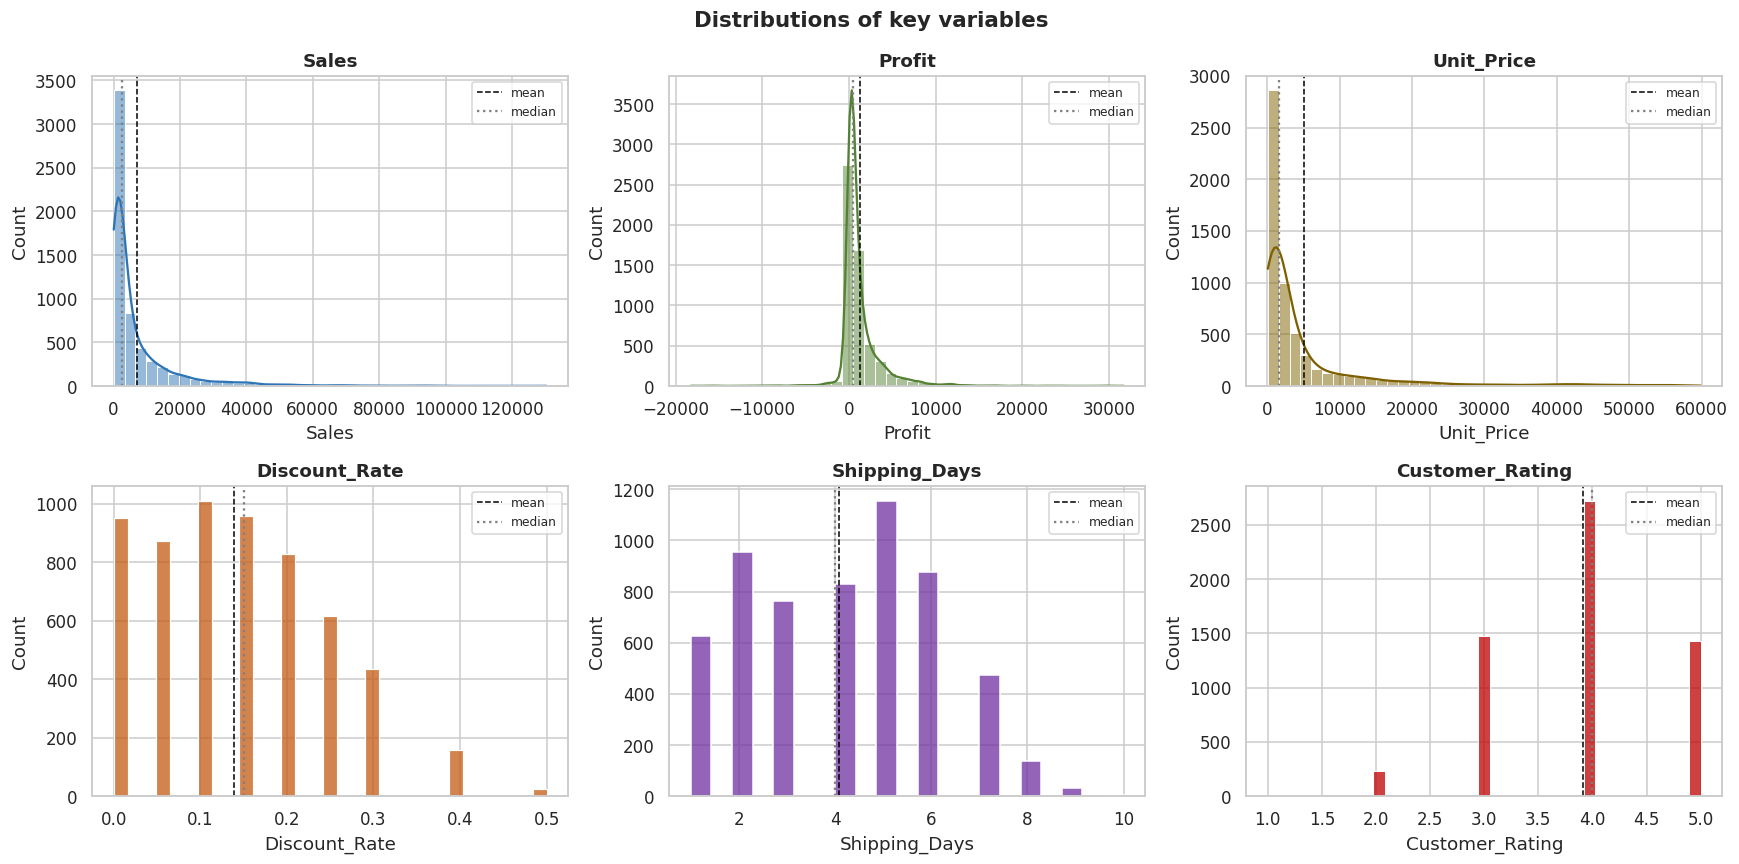

In [5]:
fig, ax = plt.subplots(2,3, figsize=(16,8))
for a,(col,color) in zip(ax.ravel(), [('Sales','#2E75B6'),('Profit','#548235'),('Unit_Price','#7F6000'),
                                       ('Discount_Rate','#C55A11'),('Shipping_Days','#7030A0'),('Customer_Rating','#C00000')]):
    sns.histplot(orders[col], bins=40 if col in('Sales','Profit','Unit_Price') else 'auto', kde=col in('Sales','Profit','Unit_Price'), color=color, ax=a)
    a.axvline(orders[col].mean(),   color='black', ls='--', lw=1, label='mean')
    a.axvline(orders[col].median(), color='grey',  ls=':',  lw=1.5, label='median')
    a.set_title(col); a.legend(fontsize=8)
plt.suptitle('Distributions of key variables', fontsize=14, fontweight='bold'); plt.tight_layout(); plt.show()

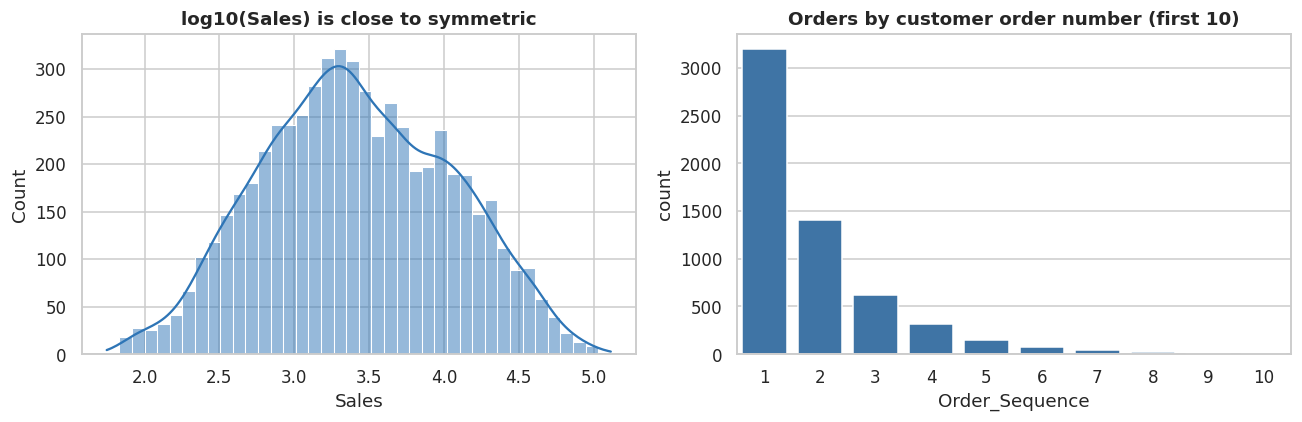

In [6]:
# Log scale makes the skewed money variables readable
fig, ax = plt.subplots(1,2, figsize=(12,4))
sns.histplot(np.log10(orders.Sales), bins=40, kde=True, color='#2E75B6', ax=ax[0]); ax[0].set_title('log10(Sales) is close to symmetric')
sns.countplot(data=orders, x='Order_Sequence', order=range(1,11), color='#2E75B6', ax=ax[1]); ax[1].set_title('Orders by customer order number (first 10)')
plt.tight_layout(); plt.show()

**Takeaways:** Sales and Unit Price are strongly right-skewed (long tail of expensive items and bulk orders) but roughly symmetric on a log scale. Discounts cluster at 5-20% with a thin tail up to 50%. Shipping days run from 1 to about 8 (peak at 5 days, the Standard mode), with very few orders beyond 8 days. The order-sequence chart shows steep drop-off after the first order, so retention is the main growth lever.

## 4. Anomaly detection: box plots and the IQR rule

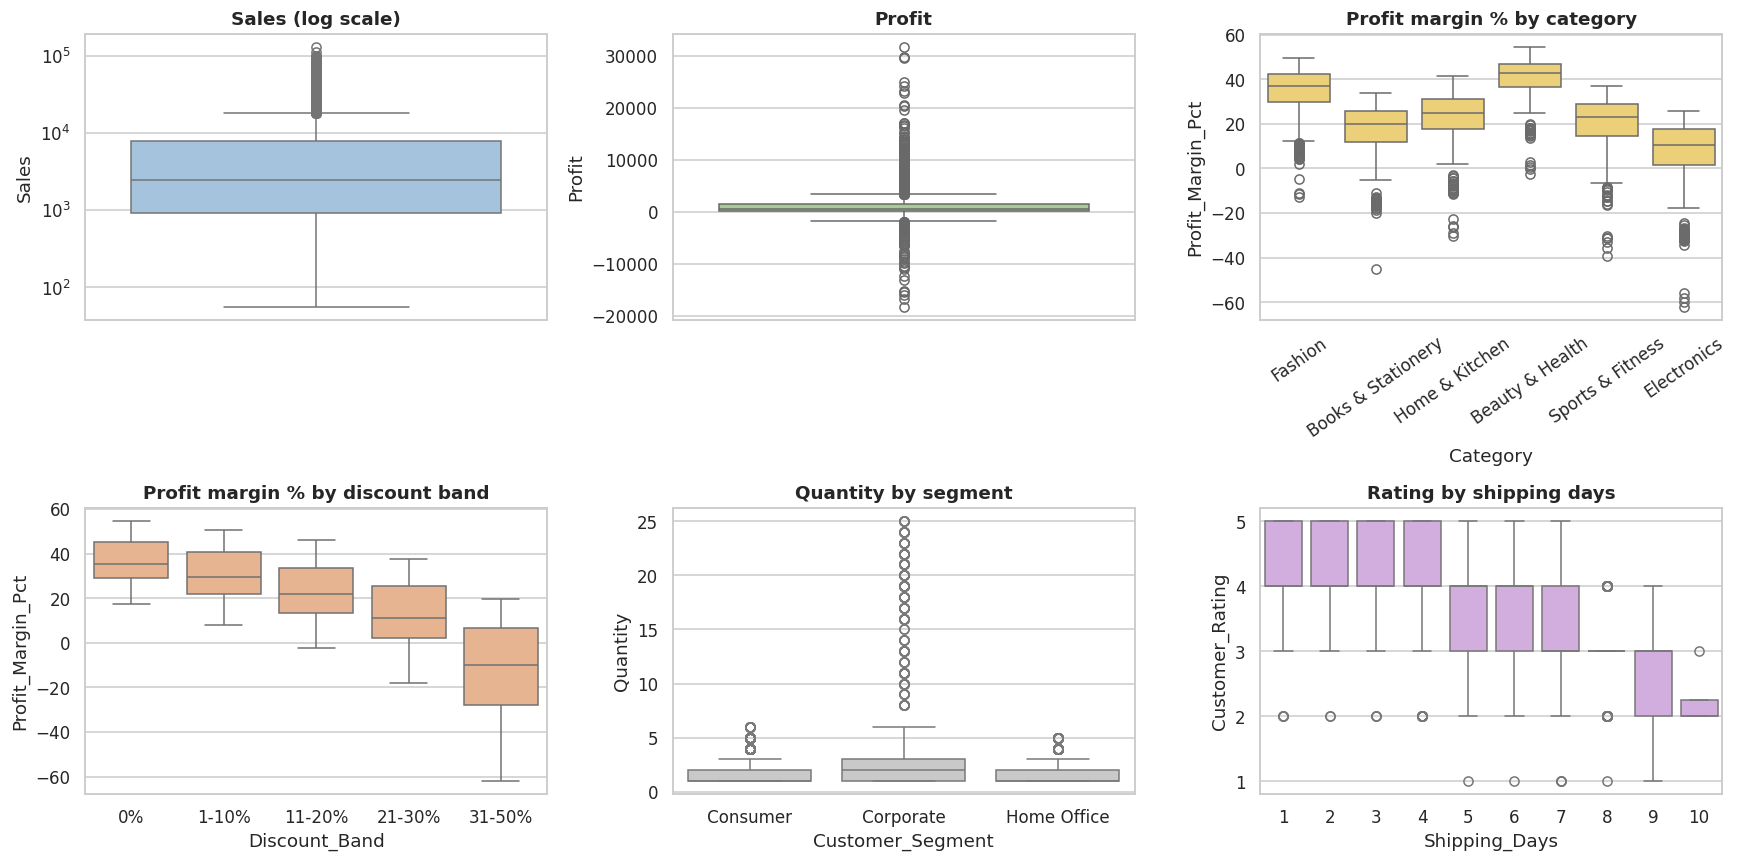

In [7]:
fig, ax = plt.subplots(2,3, figsize=(16,8))
sns.boxplot(data=orders, y='Sales', ax=ax[0,0], color='#9DC3E6'); ax[0,0].set_yscale('log'); ax[0,0].set_title('Sales (log scale)')
sns.boxplot(data=orders, y='Profit', ax=ax[0,1], color='#A9D18E'); ax[0,1].set_title('Profit')
sns.boxplot(data=orders, x='Category', y='Profit_Margin_Pct', ax=ax[0,2], color='#FFD966'); ax[0,2].tick_params(axis='x', rotation=35); ax[0,2].set_title('Profit margin % by category')
sns.boxplot(data=orders, x='Discount_Band', y='Profit_Margin_Pct', order=['0%','1-10%','11-20%','21-30%','31-50%'], ax=ax[1,0], color='#F4B183'); ax[1,0].set_title('Profit margin % by discount band')
sns.boxplot(data=orders, x='Customer_Segment', y='Quantity', ax=ax[1,1], color='#C9C9C9'); ax[1,1].set_title('Quantity by segment')
sns.boxplot(data=orders, x='Shipping_Days', y='Customer_Rating', ax=ax[1,2], color='#D5A6E6'); ax[1,2].set_title('Rating by shipping days')
plt.tight_layout(); plt.show()

In [8]:
def iqr_outliers(s):
    q1,q3 = s.quantile([.25,.75]); iqr=q3-q1
    lo,hi = q1-1.5*iqr, q3+1.5*iqr
    return ((s<lo)|(s>hi)).sum(), lo, hi
rows=[]
for c in ['Sales','Profit','Unit_Price','Quantity','Profit_Margin_Pct','Shipping_Days']:
    n,lo,hi = iqr_outliers(orders[c]); rows.append([c, n, round(n/len(orders)*100,1), round(lo,1), round(hi,1)])
pd.DataFrame(rows, columns=['Variable','Outliers','% of rows','Lower fence','Upper fence'])

,Variable,Outliers,% of rows,Lower fence,Upper fence
0,Sales,615,10.5,-9375.4,18045.6
1,Profit,707,12.1,-1831.6,3475.0
2,Unit_Price,775,13.2,-5305.0,10575.0
3,Quantity,732,12.5,-0.5,3.5
4,Profit_Margin_Pct,66,1.1,-16.1,66.8
5,Shipping_Days,0,0.0,-4.0,12.0


In [9]:
# Which kinds of orders are the outliers? Investigate rather than delete.
q1,q3 = orders.Sales.quantile([.25,.75]); hi = q3+1.5*(q3-q1)
big = orders[orders.Sales>hi]
print('High-sales outliers:', len(big), f'({len(big)/len(orders):.1%} of orders, {big.Sales.sum()/orders.Sales.sum():.1%} of revenue)')
print(big.Category.value_counts(normalize=True).round(3).head(3).to_string())
print()
print('Bulk orders (Quantity >= 8):', (orders.Quantity>=8).sum(), '| all Corporate:', (orders[orders.Quantity>=8].Customer_Segment=='Corporate').all())
loss = orders[orders.Profit<0]
print(f'Loss-making orders: {len(loss)} ({len(loss)/len(orders):.1%}) | total loss = INR {loss.Profit.sum():,.0f}')
print('Loss-making orders by discount band:'); print(loss.Discount_Band.value_counts().to_string())

High-sales outliers: 615 (10.5% of orders, 51.6% of revenue)
Category
Electronics         0.665
Home & Kitchen      0.193
Sports & Fitness    0.085

Bulk orders (Quantity >= 8): 138 | all Corporate: True
Loss-making orders: 383 (6.5%) | total loss = INR -543,956
Loss-making orders by discount band:
Discount_Band
21-30%    245
31-50%    123
11-20%     15


**Anomaly summary:** the Sales and Profit outliers are legitimate rather than data errors: expensive Electronics and Corporate bulk orders. They are kept in the data and handled with medians and rank-based tests. The *negative-profit* orders are the true business anomaly, and they are concentrated in high-discount bands.

## 5. Correlation analysis

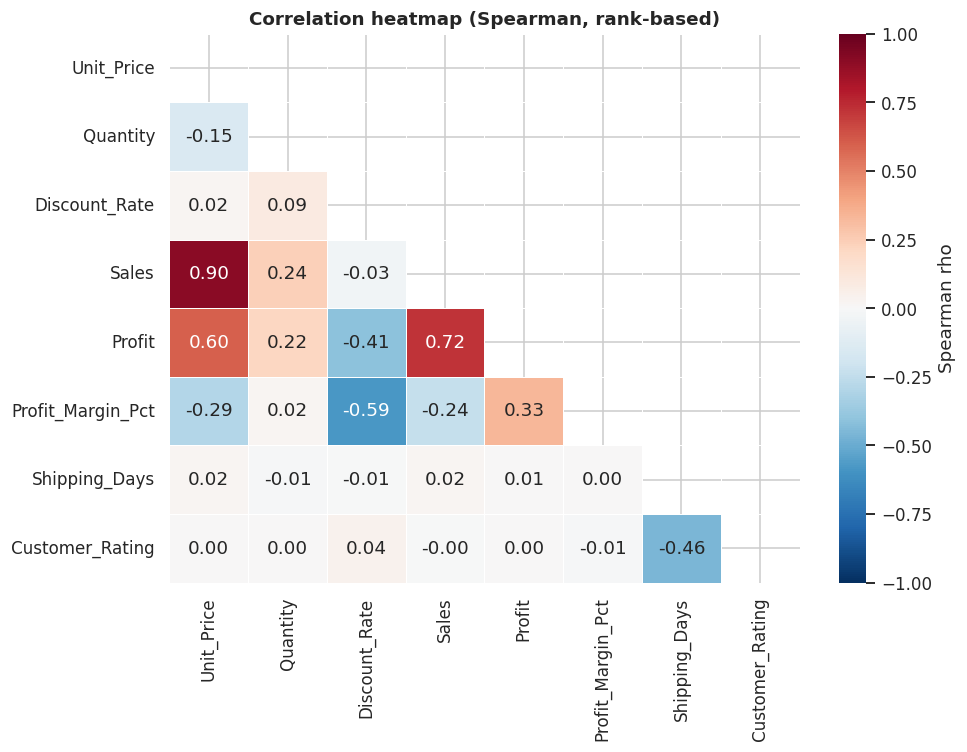

In [10]:
corr_cols = ['Unit_Price','Quantity','Discount_Rate','Sales','Profit','Profit_Margin_Pct','Shipping_Days','Customer_Rating']
corr = orders[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(9,7))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={'label':'Spearman rho'})
plt.title('Correlation heatmap (Spearman, rank-based)'); plt.tight_layout(); plt.show()

In [11]:
pairs = corr.where(~mask).stack().rename('rho').reset_index()
pairs.columns=['var1','var2','rho']
pairs['abs']=pairs.rho.abs()
pairs.sort_values('abs', ascending=False).head(8).drop(columns='abs').round(2)

,var1,var2,rho
24,Sales,Unit_Price,0.90
35,Profit,Sales,0.72
32,Profit,Unit_Price,0.60
42,Profit_Margin_Pct,Discount_Rate,-0.59
62,Customer_Rating,Shipping_Days,-0.46
34,Profit,Discount_Rate,-0.41
44,Profit_Margin_Pct,Profit,0.33
40,Profit_Margin_Pct,Unit_Price,-0.29


**Takeaways:** `Sales` is mostly driven by `Unit_Price`, and `Discount_Rate` is clearly negatively related to `Profit_Margin_Pct` (rho about -0.59). `Shipping_Days` has a clear negative relationship with `Customer_Rating`. Everything else is weak, so no multicollinearity concern for later modelling apart from the mechanical Sales/Profit/Price links.

## 6. Multivariate views

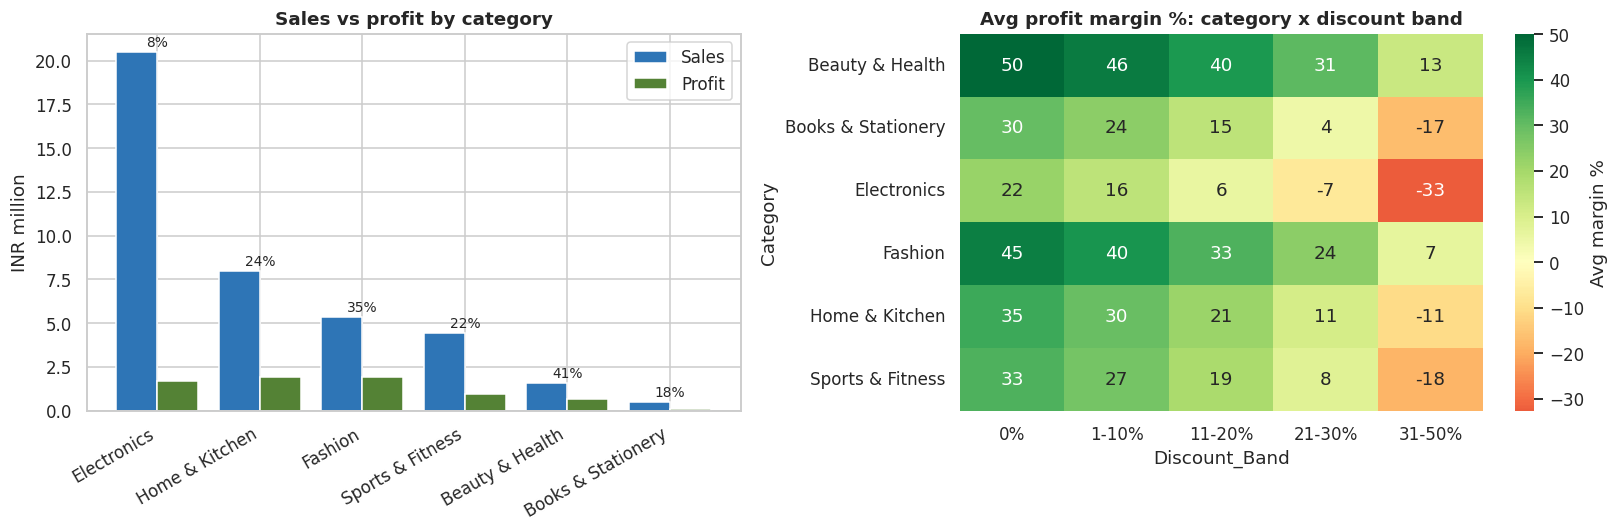

In [12]:
fig, ax = plt.subplots(1,2, figsize=(15,5))
cat = orders.groupby('Category').agg(Sales=('Sales','sum'), Profit=('Profit','sum'))
cat['Margin %'] = cat.Profit/cat.Sales*100
cat = cat.sort_values('Sales', ascending=False)
x=np.arange(len(cat)); w=.4
ax[0].bar(x-w/2, cat.Sales/1e6, w, label='Sales', color='#2E75B6'); ax[0].bar(x+w/2, cat.Profit/1e6, w, label='Profit', color='#548235')
ax[0].set_xticks(x); ax[0].set_xticklabels(cat.index, rotation=30, ha='right'); ax[0].set_ylabel('INR million'); ax[0].legend(); ax[0].set_title('Sales vs profit by category')
for i,m in enumerate(cat['Margin %']): ax[0].text(i, max(cat.Sales.iloc[i],cat.Profit.iloc[i])/1e6+.3, f'{m:.0f}%', ha='center', fontsize=9)
heat = orders.pivot_table(index='Category', columns='Discount_Band', values='Profit_Margin_Pct', aggfunc='mean')[['0%','1-10%','11-20%','21-30%','31-50%']]
sns.heatmap(heat, annot=True, fmt='.0f', cmap='RdYlGn', center=0, ax=ax[1], cbar_kws={'label':'Avg margin %'}); ax[1].set_title('Avg profit margin %: category x discount band')
plt.tight_layout(); plt.show()

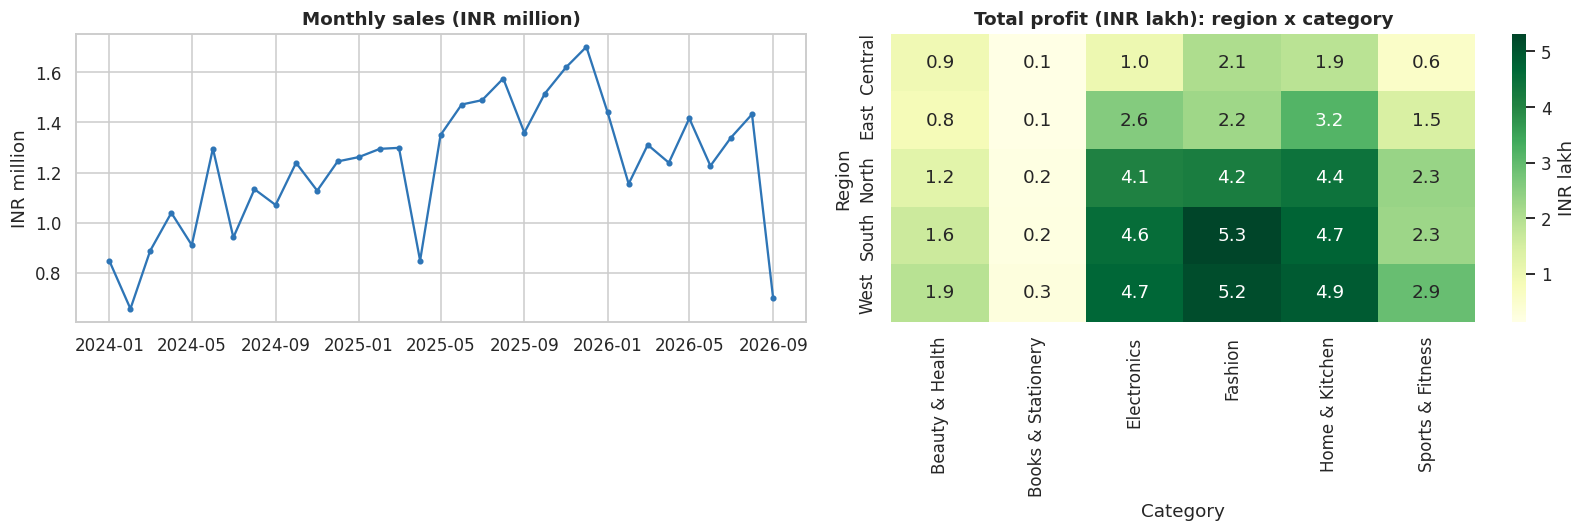

In [13]:
fig, ax = plt.subplots(1,2, figsize=(15,5))
orders['Month'] = orders.Order_Date.dt.to_period('M').dt.to_timestamp()
m = orders.groupby('Month').agg(Sales=('Sales','sum'), Orders=('Order_ID','count'))
ax[0].plot(m.index, m.Sales/1e6, marker='o', ms=3, color='#2E75B6'); ax[0].set_title('Monthly sales (INR million)'); ax[0].set_ylabel('INR million')
sns.heatmap(orders.pivot_table(index='Region', columns='Category', values='Profit', aggfunc='sum')/1e5, annot=True, fmt='.1f', cmap='YlGn', ax=ax[1], cbar_kws={'label':'INR lakh'})
ax[1].set_title('Total profit (INR lakh): region x category')
plt.tight_layout(); plt.show()

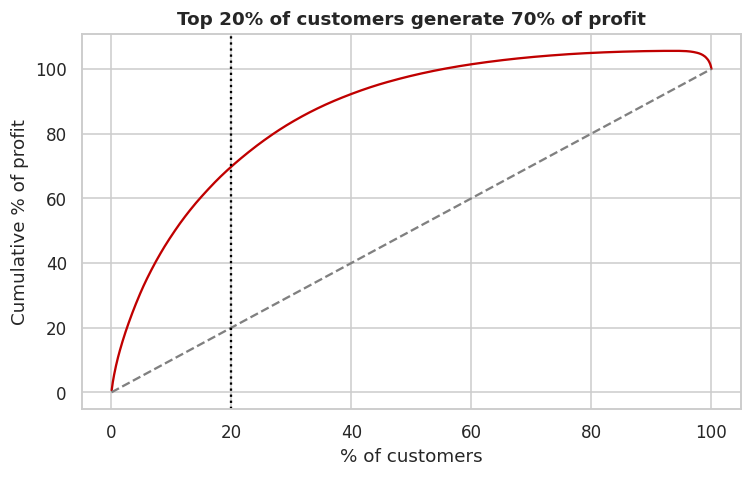

In [14]:
# Customer value concentration (Pareto)
cs = cust.sort_values('Total_Profit', ascending=False).reset_index(drop=True)
cs['cum_profit_%'] = cs.Total_Profit.cumsum()/cs.Total_Profit.sum()*100
cs['cust_%'] = (cs.index+1)/len(cs)*100
top20 = cs.loc[cs['cust_%']<=20,'Total_Profit'].sum()/cs.Total_Profit.sum()
plt.figure(figsize=(7,4.5)); plt.plot(cs['cust_%'], cs['cum_profit_%'], color='#C00000'); plt.plot([0,100],[0,100], ls='--', color='grey')
plt.axvline(20, color='black', ls=':'); plt.title(f'Top 20% of customers generate {top20:.0%} of profit'); plt.xlabel('% of customers'); plt.ylabel('Cumulative % of profit'); plt.tight_layout(); plt.show()

## 7. Hypothesis tests
All tests use a significance level of **alpha = 0.05**. Money variables are skewed, so rank-based tests are preferred.

| # | Business question | H0 | H1 | Test |
|---|---|---|---|---|
| H1 | Is customer retention related to discount depth? | Repeat rate is the same across discount bands | Repeat rate differs by band | Chi-square test of independence (plus Mann-Whitney on mean discount) |
| H2 | Do deeper discounts change profitability? | Profit margin is the same in all discount bands | At least one band differs | Kruskal-Wallis (+ Spearman correlation) |
| H3 | Does slower delivery lower satisfaction? | No monotonic relationship between shipping days and rating | Negative relationship | Spearman correlation |

### H1: Customer retention vs discount rate

Repeat_Customer    0    1  Repeat rate %
Discount_Group                          
<=5%             588  234           28.5
5-10%            301  326           52.0
10-20%           526  571           52.1
20-30%           321  234           42.2
>30%              61   38           38.4

Chi-square = 127.7, dof = 4, p = 1.21e-26  -> REJECT H0

Mean discount: repeat 13.97% vs one-time 13.73% (Mann-Whitney p = 0.027)


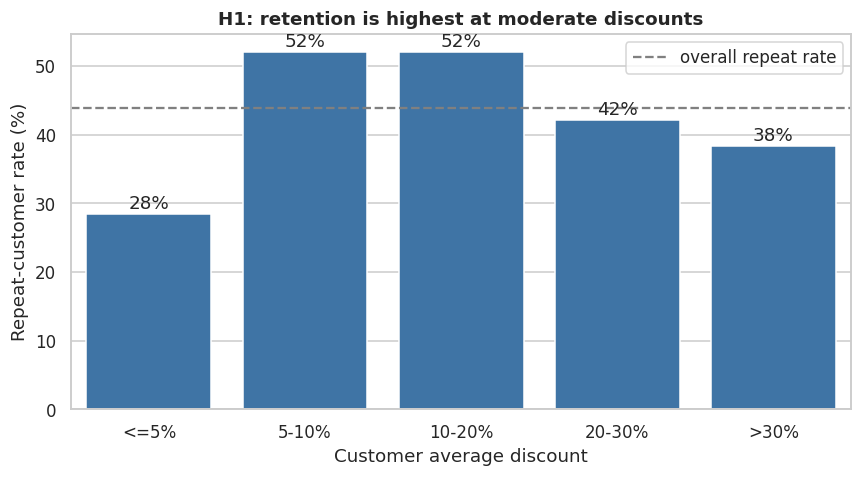

In [15]:
cust['Discount_Group'] = pd.cut(cust.Avg_Discount_Rate, [-.01,.05,.10,.20,.30,.60], labels=['<=5%','5-10%','10-20%','20-30%','>30%'])
ct = pd.crosstab(cust.Discount_Group, cust.Repeat_Customer)
rate = (ct[1]/ct.sum(axis=1)*100).round(1)
chi2, p, dof, _ = stats.chi2_contingency(ct)
print(ct.assign(**{'Repeat rate %':rate}).to_string()); print()
print(f'Chi-square = {chi2:.1f}, dof = {dof}, p = {p:.2e}  ->', 'REJECT H0' if p<.05 else 'fail to reject H0')
rep = cust[cust.Repeat_Customer==1].Avg_Discount_Rate; one = cust[cust.Repeat_Customer==0].Avg_Discount_Rate
u,p2 = stats.mannwhitneyu(rep, one)
print(f'\nMean discount: repeat {rep.mean():.2%} vs one-time {one.mean():.2%} (Mann-Whitney p = {p2:.3f})')
plt.figure(figsize=(8,4.5)); ax=sns.barplot(x=rate.index.astype(str), y=rate.values, color='#2E75B6')
for i,v in enumerate(rate.values): ax.text(i, v+.8, f'{v:.0f}%', ha='center')
ax.axhline(cust.Repeat_Customer.mean()*100, ls='--', color='grey', label='overall repeat rate'); ax.legend()
plt.xlabel('Customer average discount'); plt.ylabel('Repeat-customer rate (%)'); plt.title('H1: retention is highest at moderate discounts'); plt.tight_layout(); plt.show()

**Conclusion H1: reject H0.** Retention depends strongly on discount depth, but **not linearly**. Customers who get almost no discount (<=5%) repeat the least, those at 5-20% repeat the most (about 52%), and heavy-discount customers fall back to about 38-42%, which suggests deal-seekers who do not return. The overall mean discounts of repeat and one-time customers are almost identical, so a simple average comparison would have hidden this pattern.

### H2: Discount level vs profit margin

Kruskal-Wallis H = 1985, p = 0.00e+00  -> REJECT H0
Spearman rho (discount vs margin %) = -0.59, p = 0.0e+00



,Orders,Avg_margin_pct,Median_profit,Loss_making_share
Discount_Band,,,,
0%,950,36.199,916.035,0.000
1-10%,1884,30.363,809.760,0.000
11-20%,1785,22.331,450.810,0.008
21-30%,1050,12.045,151.930,0.233
31-50%,183,-10.375,-111.060,0.672


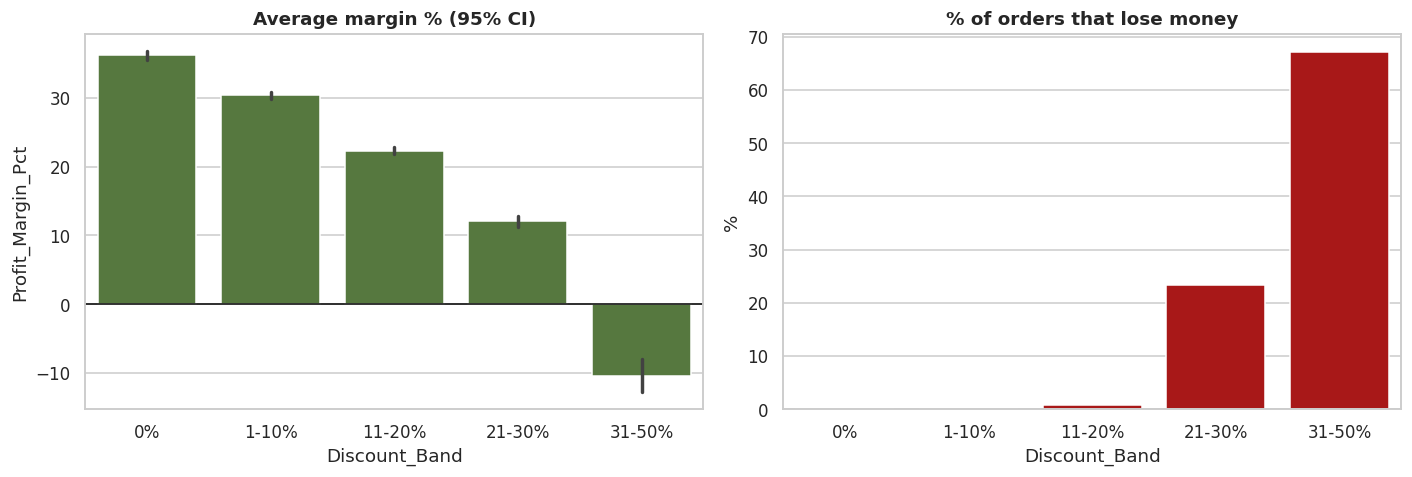

In [16]:
order_bands = ['0%','1-10%','11-20%','21-30%','31-50%']
groups = [orders.loc[orders.Discount_Band==b,'Profit_Margin_Pct'] for b in order_bands]
H,p = stats.kruskal(*groups)
print(f'Kruskal-Wallis H = {H:.0f}, p = {p:.2e}  ->', 'REJECT H0' if p<.05 else 'fail to reject H0')
rho,p = stats.spearmanr(orders.Discount_Rate, orders.Profit_Margin_Pct)
print(f'Spearman rho (discount vs margin %) = {rho:.2f}, p = {p:.1e}\n')
summary = orders.groupby('Discount_Band').agg(Orders=('Order_ID','count'), Avg_margin_pct=('Profit_Margin_Pct','mean'),
          Median_profit=('Profit','median'), Loss_making_share=('Profit', lambda s:(s<0).mean())).loc[order_bands]
display(summary.round(3))
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=orders, x='Discount_Band', y='Profit_Margin_Pct', order=order_bands, errorbar=('ci',95), color='#548235', ax=ax[0]); ax[0].axhline(0,color='black',lw=1); ax[0].set_title('Average margin % (95% CI)')
sns.barplot(x=summary.index, y=summary.Loss_making_share*100, color='#C00000', ax=ax[1]); ax[1].set_title('% of orders that lose money'); ax[1].set_ylabel('%')
plt.tight_layout(); plt.show()

**Conclusion H2: reject H0.** Margin falls steadily as discounts deepen, from about 36% at no discount to about -10% in the 31-50% band. Loss-making orders appear at roughly 20% discount and above: about 23% of orders in the 21-30% band and about 67% in the 31-50% band. By category (heatmap in section 6): Electronics turns loss-making in the 21-30% band; Books, Home & Kitchen and Sports & Fitness turn negative in the 31-50% band; Fashion and Beauty & Health stay positive even at 31-50%.

### H3: Shipping delay vs customer rating

Spearman rho = -0.46, p = 2.9e-299  -> REJECT H0
Avg rating: <=3 days 4.28 | >=6 days 3.34 | difference 0.94
Mann-Whitney p = 4.7e-249


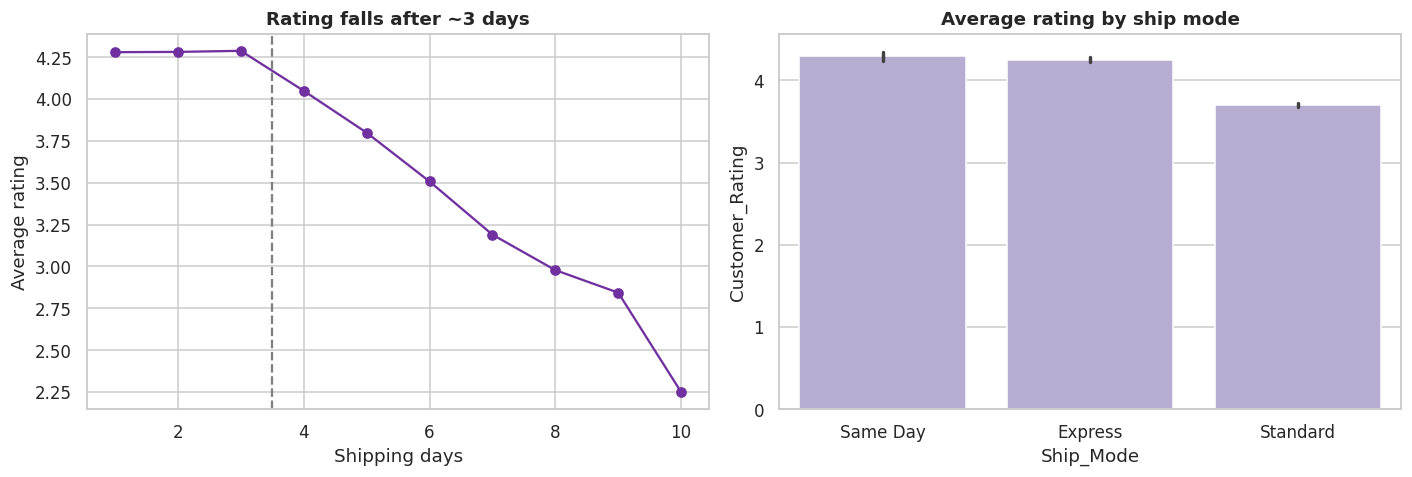

In [17]:
rho,p = stats.spearmanr(orders.Shipping_Days, orders.Customer_Rating)
print(f'Spearman rho = {rho:.2f}, p = {p:.1e}  ->', 'REJECT H0' if p<.05 else 'fail to reject H0')
fast = orders[orders.Shipping_Days<=3].Customer_Rating; slow = orders[orders.Shipping_Days>=6].Customer_Rating
print(f'Avg rating: <=3 days {fast.mean():.2f} | >=6 days {slow.mean():.2f} | difference {fast.mean()-slow.mean():.2f}')
print('Mann-Whitney p =', f"{stats.mannwhitneyu(fast, slow).pvalue:.1e}")
avg = orders.groupby('Shipping_Days').Customer_Rating.mean()
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
ax[0].plot(avg.index, avg.values, marker='o', color='#7030A0'); ax[0].axvline(3.5, ls='--', color='grey'); ax[0].set_xlabel('Shipping days'); ax[0].set_ylabel('Average rating'); ax[0].set_title('Rating falls after ~3 days')
sns.barplot(data=orders, x='Ship_Mode', y='Customer_Rating', order=['Same Day','Express','Standard'], color='#B4A7D6', ax=ax[1]); ax[1].set_title('Average rating by ship mode')
plt.tight_layout(); plt.show()

**Conclusion H3: reject H0.** There is a moderate negative monotonic relationship (rho about -0.46). Ratings are flat at about 4.3 up to 3 days and then decline roughly 0.25-0.5 points per extra day, down to about 2.3 at 10 days. Delivery speed above 3 days is the clearest lever on satisfaction in this data.

## 8. Top 5 critical findings

**1. Deep discounts (above about 25-30%) are destroying profit.**
Average margin goes from about 36% (no discount) to about -10% in the 31-50% band, where roughly two out of three orders lose money (Electronics already turns negative at 21-30%). Across all bands, 383 loss-making orders (6.5% of orders) wiped out about INR 5.4 lakh of profit, equal to about 7.5% of total net profit of INR 72.1 lakh. *Action:* cap discounts at 20-25% and require approval above that.

**2. Retention follows an inverted-U with discount depth, not "more discount = more loyalty".**
Repeat-purchase rate is about 28% for customers with almost no discount, about 52% in the 5-20% range, and drops to about 38-42% for heavy-discount customers (chi-square p < 1e-20). Deep discounting attracts one-time deal-seekers while costing margin. *Action:* target a 5-20% discount range and use non-price incentives (loyalty perks, faster delivery) to retain customers.

**3. Delivery speed above 3 days damages satisfaction.**
Average rating is flat at about 4.3 for 1-3 days, then falls to about 3.5 at 6 days and about 2.3 at 10 days, though only 4 orders took 10 days (Spearman rho about -0.46). *Action:* fix the slow tail first, especially East and Central regions on Standard shipping, and consider upgrading orders that would breach 3 days.

**4. Electronics drives revenue but not profit.**
Electronics is about 51% of revenue (INR 2.05 crore) but only about 24% of profit, with an average margin of about 8% against 35-41% for Fashion and Beauty & Health. Fashion and Home & Kitchen deliver more profit from far less revenue. Fashion also has the highest return rate (8.5%). *Action:* review electronics pricing and discounting first, as any discount there erases margin quickly.

**5. Value is highly concentrated and sales are heavily right-skewed.**
The top 20% of customers generate about 70% of profit (and about 65% of sales). Sales has skewness of about 3.5 and about 10.5% of orders are statistical outliers, driven by expensive electronics and Corporate bulk orders (Corporate has the highest average order value). Averages overstate typical orders, so use medians for reporting. *Action:* protect and grow the top-value and Corporate customers with dedicated retention programmes.

---
**Limitations & next steps:** the data is synthetic, so effect sizes illustrate method rather than real market behaviour. The tests show association, not causation (a randomised discount experiment would be needed). Next steps could include a retention model (logistic regression on first-order features) and RFM segmentation.